In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)

from google.colab import files
uploaded = files.upload()   # pick diabetes_prediction_dataset.csv
df = pd.read_csv("diabetes_prediction_dataset.csv")
print(df.shape)
df.head()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset (1).csv
(100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64 

Duplicates: 3854
Shape: (96128, 9)
diabetes
0    0.912
1    0.088
Name: proportion, dtype: float64


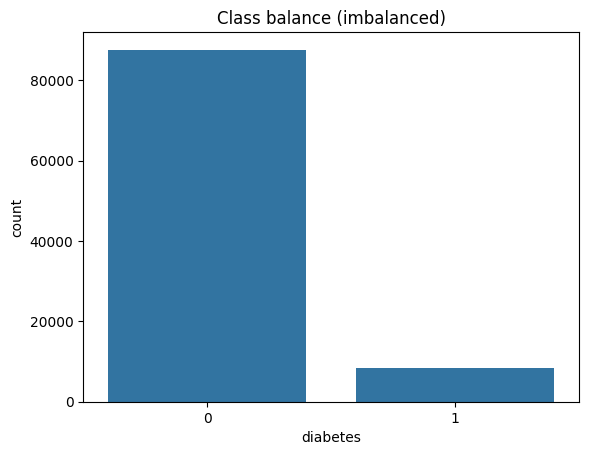

In [2]:
print(df.isna().sum(), "\n")
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
df = df[df["gender"] != "Other"].reset_index(drop=True)   # only a handful of rows

print("Shape:", df.shape)
print(df["diabetes"].value_counts(normalize=True).round(3))
sns.countplot(x="diabetes", data=df)
plt.title("Class balance (imbalanced)")
plt.show()

In [3]:
X = df.drop(columns="diabetes")
y = df["diabetes"]

num_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level", "hypertension", "heart_disease"]
cat_cols = ["gender", "smoking_history"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [4]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree":       DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=200, max_depth=12, n_jobs=-1, random_state=42),
    "KNN":                 KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
}

fitted, results = {}, []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    fitted[name] = pipe
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1-score":  f1_score(y_test, y_pred),
        "ROC-AUC":   roc_auc_score(y_test, y_prob),
    })

In [5]:
metrics_df = pd.DataFrame(results).set_index("Model").round(4).sort_values("F1-score", ascending=False)
display(metrics_df.style.highlight_max(axis=0, color="lightgreen"))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,0.971800,0.998300,0.681600,0.810100,0.970200
Decision Tree,0.971800,1.000000,0.679800,0.809400,0.960900
Logistic Regression,0.959000,0.860200,0.638600,0.733000,0.959600
KNN,0.960600,0.951900,0.583100,0.723200,0.941500


Best model: Random Forest 

              precision    recall  f1-score   support

 No diabetes       0.97      1.00      0.98     17530
    Diabetes       1.00      0.68      0.81      1696

    accuracy                           0.97     19226
   macro avg       0.98      0.84      0.90     19226
weighted avg       0.97      0.97      0.97     19226



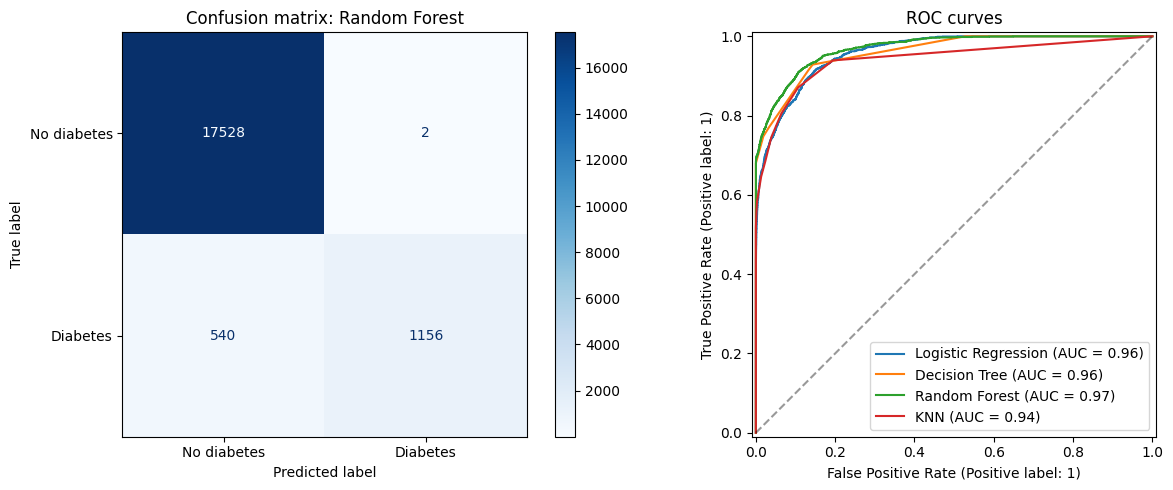

TN=17528, FP=2, FN=540, TP=1156


In [6]:
best_name = metrics_df["F1-score"].idxmax()
best_model = fitted[best_name]
print("Best model:", best_name, "\n")

y_pred_best = best_model.predict(X_test)
print(classification_report(y_test, y_pred_best, target_names=["No diabetes", "Diabetes"]))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_test, y_pred_best)
ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"]).plot(ax=ax[0], cmap="Blues", values_format="d")
ax[0].set_title(f"Confusion matrix: {best_name}")

for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=ax[1], name=name)
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[1].set_title("ROC curves")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

In [7]:
b = metrics_df.loc[best_name]
print(
    f"{best_name} is selected because it has the best F1-score ({b['F1-score']:.3f}) and a ROC-AUC of {b['ROC-AUC']:.3f}, "
    f"which matters on this imbalanced dataset where accuracy ({b['Accuracy']:.3f}) alone is misleading. "
    f"It has high precision ({b['Precision']:.3f}) with recall of {b['Recall']:.3f}, so it produces {fp} false alarms "
    f"but misses {fn} diabetic cases. If catching every diabetic matters most, a lower decision threshold "
    f"can be used to trade some precision for higher recall."
)

Random Forest is selected because it has the best F1-score (0.810) and a ROC-AUC of 0.970, which matters on this imbalanced dataset where accuracy (0.972) alone is misleading. It has high precision (0.998) with recall of 0.682, so it produces 2 false alarms but misses 540 diabetic cases. If catching every diabetic matters most, a lower decision threshold can be used to trade some precision for higher recall.
